# Day 5 - Exploratory Data Analysis Well-Log & Lithology

Saat mengebor sumur (untuk minyak, gas, atau eksplorasi mineral), alat ukur diturunkan ke dalam lubang bor dan merekam **log sumur** (*well-log*): sinar gamma, kepadatan batuan, porositas, dan lainnya pada tiap kedalaman. Dari log ini, geolog menyimpulkan **litologi** — jenis batuan yang dilewati.


Notebook ini mengeksplorasi log dari satu sumur nyata di Laut Utara.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konsep **log sumur** & **litologi**.
> - Membuang kolom yang seluruhnya kosong (all-NaN).
> - Membaca sebaran log (GR, RHOB, NPHI) & komposisi jenis batuan.
> - Membuat **plot log vs kedalaman** (sumbu kedalaman dibalik) — visual khas geosains.

## About the Dataset

**Well Logs Dataset for Machine Learning** — rekaman log dari satu sumur (34/10-16 R, Laut Utara), lengkap dengan label litologi pada tiap kedalaman.

- **Sumber:** [Kaggle — faresazzam/well-logs-dataset-for-machine-learning](https://www.kaggle.com/datasets/faresazzam/well-logs-dataset-for-machine-learning)
- **Ukuran:** 25.095 baris × 27 kolom (tiap baris = satu titik kedalaman)

| Kolom | Arti |
|-------|------|
| `DEPTH_MD` | Kedalaman terukur (meter) |
| `GR` | Sinar gamma (indikasi lempung/shale) |
| `RHOB` | Densitas batuan (bulk density) |
| `NPHI` | Porositas neutron |
| `DTC` | Waktu tempuh sonik (kompresi) |
| `PEF` | Faktor fotolistrik (petunjuk jenis mineral) |
| `RDEP` | Resistivitas dalam |
| `CALI` | Diameter lubang bor (caliper) |
| `SP` | Potensial spontan |
| `GROUP` | **Label litologi** (kelompok batuan) |

*Beberapa kolom seluruhnya kosong (SGR, BS, ROP, DTS, DCAL, MUDWEIGHT, RMIC, ROPA, RXO) — Saya akan buang.*

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import the Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d faresazzam/well-logs-dataset-for-machine-learning
!unzip well-logs-dataset-for-machine-learning.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/faresazzam/well-logs-dataset-for-machine-learning
License(s): MIT
100% 20.2M/20.2M [00:00<00:00, 47.0MB/s]

Archive:  well-logs-dataset-for-machine-learning.zip
  inflating: 15_9-23.csv             
  inflating: 15_9_14_well.csv        
  inflating: 16_2-7.csv              
  inflating: 16_7-6.csv              
  inflating: 17_4-1.csv              
  inflating: 25_10-9.csv             
  inflating: 25_10_10_well.csv       
  inflating: 25_11_24_well.csv       
  inflating: 25_5_3_well.csv         
  inflating: 29_3_1_well.csv         
  inflating: 31_2-10.csv             
  inflating: 31_2-21 S.csv           
  inflating: 31_6-5.csv              
  inflating: 31_6-8.csv              
  inflating: 34_10_16_R_well.csv     
  inflating: 34_3-2 S.csv            
  inflating: 34_3_3_A_well.csv       
  inflating: 34

saya akan menggunakan file: 34_10_16_R_well.csv

## Initial Exploration

In [4]:
df = pd.read_csv('34_10_16_R_well.csv')
df.head()

,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,...,SP,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO
0,34/10-16 R,227.296008,455758.28125,6773609.0,-205.295288,NORDLAND GP.,NaN,15.350845,2.064793,2.008468,...,61.013443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.064793
1,34/10-16 R,227.448008,455758.28125,6773609.0,-205.447296,NORDLAND GP.,NaN,15.259828,2.078203,2.232328,...,59.488522,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.078203
2,34/10-16 R,227.600008,455758.28125,6773609.0,-205.599289,NORDLAND GP.,NaN,15.264132,2.168267,2.342432,...,60.286034,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.168267
3,34/10-16 R,227.752008,455758.28125,6773609.0,-205.751297,NORDLAND GP.,NaN,15.251912,2.309140,2.415552,...,59.864864,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.309140
4,34/10-16 R,227.904008,455758.28125,6773609.0,-205.903290,NORDLAND GP.,NaN,15.250000,2.300423,2.474846,...,59.241470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.300423


Mari lihat kolom, tipe, dan berapa banyak yang kosong.

In [5]:
df.isnull().mean().mul(100).round(2).sort_values(ascending=False)

,0
RMIC,100.00
BS,100.00
SGR,100.00
ROP,100.00
DTS,100.00
DCAL,100.00
MUDWEIGHT,100.00
ROPA,100.00
NPHI,33.77
FORMATION,16.54


**Interpretation:**

Hasil diatas menunjukkan **persentase data kosong** di tiap kolom pada dataset *well logging* (data sumur/geofisika), diurutkan dari yang paling banyak kosong:

* **Kosong total (100.00%):**
  - Ada 8 kolom (`RMIC`, `BS`, `SGR`, `ROP`, `DTS`, `DCAL`, `MUDWEIGHT`, `ROPA`) yang **tidak punya data sama sekali** (semua baris kosong). Kolom ini umumnya langsung dibuang (`drop`).
* **Kosong sedang–tinggi (9.51% – 33.77%):**
  - Kolom `NPHI` (33.77%), `FORMATION` (16.54%), dan `DRHO` (9.51%) punya porsi kosong yang cukup terasa. Perlu dicek apakah kosongnya acak atau karena kedalaman tertentu sebelum memutuskan dibuang atau diisi.
* **Kosong sangat sedikit (0.12% – 0.79%):**
  - Kolom `PEF`, `RSHA`, `RXO`, `DTC`, `CALI`, dan `RMED` hampir lengkap. Biasanya aman diisi (misalnya dengan median/interpolasi sesuai kedalaman) atau baris kosongnya dihapus jika jumlahnya sedikit.
* **Lengkap 100% (0.00%):**
  - Kolom `X_LOC` sampai `RHOB` (10 kolom terbawah) **tidak ada data yang kosong** sama sekali dan siap dipakai.

**Intinya:** buang dulu 8 kolom yang 100% kosong, lalu tangani kolom yang kosong sebagian sesuai kebutuhan analisis/model.

## Cleanup: Discard all-NaN Columns & Select Useful Logs

In [7]:
from collections import defaultdict
logam_all_nan = ["SGR", "BS", "ROP", "DTS", "DCAL", "MUDWEIGHT", "RMIC", "ROPA"]
df = df.drop(columns=[k for k in logam_all_nan if k in df.columns])

logam_use = ["DEPTH_MD", "GR", "RHOB", "NPHI", "DTC", "PEF", "RDEP", "CALI", "SP", "GROUP"]
df_use = df[[k for k in logam_use if k in df.columns]].copy()


print("Kolom terpakai:", list(df_use.columns))
print("Ukuran dataset:", df_use.shape)
df_use.describe().round(2).T

Kolom terpakai: ['DEPTH_MD', 'GR', 'RHOB', 'NPHI', 'DTC', 'PEF', 'RDEP', 'CALI', 'SP', 'GROUP']
Ukuran dataset: (25095, 10)


,count,mean,std,min,25%,50%,75%,max
DEPTH_MD,25095.0,2134.47,1101.20,227.30,1180.87,2134.44,3088.01,4042.04
GR,25095.0,51.91,17.33,12.88,39.26,52.69,62.39,152.88
RHOB,25095.0,2.20,0.26,1.38,2.02,2.16,2.42,2.90
NPHI,16621.0,0.35,0.11,0.01,0.28,0.37,0.43,0.68
DTC,25027.0,118.40,27.75,59.23,97.07,113.19,144.31,172.71
PEF,24897.0,9.74,17.77,1.43,3.26,4.93,10.04,382.12
RDEP,25095.0,3.63,14.76,0.45,1.00,1.66,2.68,499.73
CALI,25060.0,14.22,3.24,8.32,12.46,14.32,16.79,25.55
SP,25095.0,65.25,11.35,33.36,53.78,69.47,75.67,86.24


**Interpretation:**

Ringkasan statistik dari **25.095 baris** dan **10 kolom terpilih** (9 numerik + `GROUP` yang bersifat kategorikal sehingga tidak muncul di tabel numerik):

1. Kelengkapan Data (`count`)

    * **Lengkap (25.095 baris):** `DEPTH_MD`, `GR`, `RHOB`, `RDEP`, dan `SP` tidak ada nilai kosong.
    * **Masih ada yang kosong:** `NPHI` (16.621 terisi, sekitar 33,8% kosong), `PEF` (24.897 terisi), `DTC` (25.027 terisi), dan `CALI` (25.060 terisi).

2. Gambaran Nilai & Sebaran (`mean`, `std`, `min`–`max`)

   * **`DEPTH_MD`:** Kedalaman terukur merata dari **227,30** hingga **4.042,04**, dengan rata-rata dan median sama-sama di sekitar **2.134,4**.
    * **`GR`:** Rata-rata **51,91** (median **52,69**), rentang **12,88–152,88**, sebaran cukup stabil (`std` 17,33).
    * **`RHOB`:** Rata-rata **2,20** (median **2,16**), rentang sempit **1,38–2,90** (`std` 0,26).
    * **`NPHI`:** Rata-rata **0,35** (median **0,37**), nilai berada di antara **0,01–0,68** (`std` 0,11).
    * **`DTC`:** Rata-rata **118,40** (median **113,19**), rentang **59,23–172,71** (`std` 27,75).
    * **`CALI`:** Rata-rata **14,22** (median **14,32**), rentang **8,32–25,55** (`std` 3,24).
    * **`SP`:** Rata-rata **65,25** (median **69,47**), rentang **33,36–86,24** (`std` 11,35).

3. Perhatikan Nilai Ekstrem / *Skewness* (`mean` vs `50%` dan `max`)

    * **`PEF` & `RDEP`:** Nilai rata-rata jauh lebih tinggi daripada median (`PEF`: rata-rata **9,74** vs median **4,93**; `RDEP`: rata-rata **3,63** vs median **1,66**) dan punya nilai maksimum yang melonjak jauh (`382,12` dan `499,73`). Ini tanda distribusi miring ke kanan (*right-skewed*) akibat lonjakan nilai tinggi di titik tertentu.

**Intinya:** Dataset sudah diperkecil ke 10 kolom inti dengan 25.095 baris, sebagian besar kolom sudah lengkap dan stabil, `NPHI` masih paling banyak kosong, dan `PEF`/`RDEP` memiliki lonjakan nilai tinggi yang perlu dicermati sebelum pemodelan.

## Exploratory Data Analysis & Visualization

### a) GR & RHOB logs vs. depth (track plot)

Ini visual paling khas di geosains: kedalaman di sumbu **Y yang dibalik** (dangkal di atas, dalam di bawah).

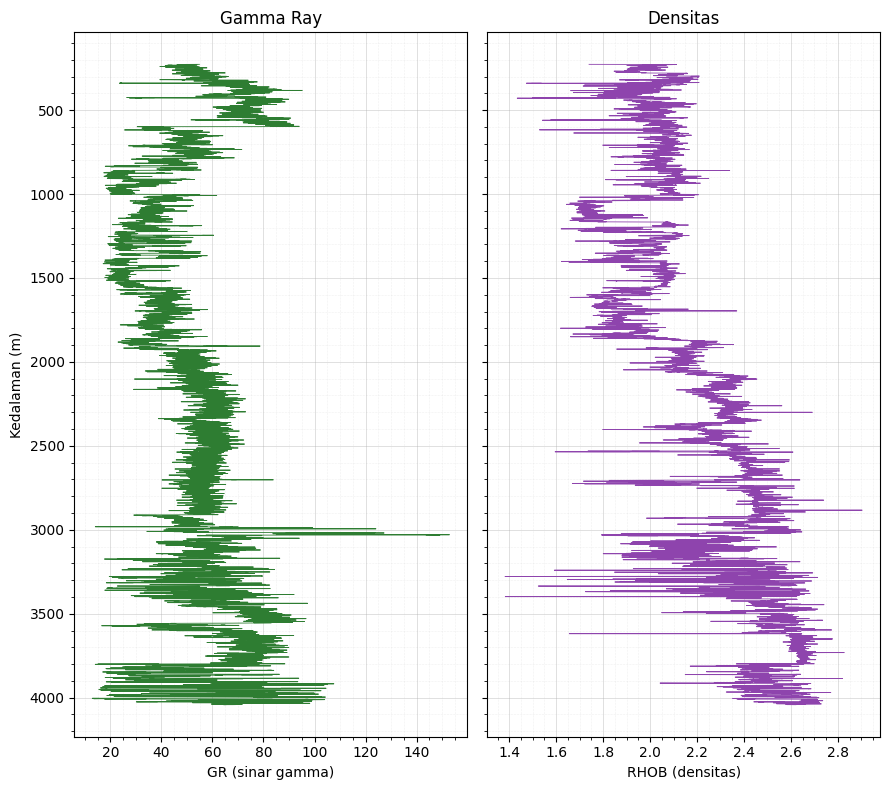

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

tracks = [
    {
        "col": "GR",
        "xlabel": "GR (sinar gamma)",
        "title": "Gamma Ray",
        "color": "#2E7D32",
    },
    {
        "col": "RHOB",
        "xlabel": "RHOB (densitas)",
        "title": "Densitas",
        "color": "#8E44AD",
    },
]

fig, axes = plt.subplots(1, len(tracks), figsize=(4.5 * len(tracks), 8), sharey=True)
axes = list(axes) if len(tracks) > 1 else [axes]

for idx, (ax, spec) in enumerate(zip(axes, tracks)):
    ax.plot(df_use[spec["col"]], df_use["DEPTH_MD"], color=spec["color"], linewidth=0.6)
    ax.set_xlabel(spec["xlabel"])
    ax.set_title(spec["title"])

    # Aktifkan grid utama (kotak besar) dan grid minor (kotak kecil)
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax.grid(True, which="major", linestyle="-", linewidth=0.6, alpha=0.45)
    ax.grid(True, which="minor", linestyle=":", linewidth=0.4, alpha=0.35)

    if idx == 0:
        ax.set_ylabel("Kedalaman (m)")
        ax.invert_yaxis()

plt.tight_layout()
plt.show()

**Interpretation:**

Plot *well log* ini memperlihatkan perubahan **Gamma Ray (GR)** dan **Densitas (RHOB)** dari kedalaman dangkal (sekitar **227 m**) di bagian atas hingga dalam (sekitar **4.042 m**) di bagian bawah.

1. Gamma Ray (Hijau)

    * Kurva naik-turun tajam di sepanjang kedalaman, menandakan lapisan batuan yang berganti-ganti (misalnya peralihan antara lapisan ber-GR rendah dan tinggi).
    * Nilai umumnya berada di kisaran **40–70**, dengan beberapa lonjakan tinggi mencapai **100–150** (terutama di sekitar kedalaman ~3.000 m dan menjelang ~3.900–4.000 m).

2. Densitas / RHOB (Ungu)

    * Secara umum, densitas batuan cenderung **meningkat ke arah kedalaman yang lebih besar** (dari kisaran ~1,8–2,2 di bagian atas menjadi ~2,4–2,6 di bagian yang lebih dalam), karena tekanan dan pemadatan batuan bertambah.
    * Ada fluktuasi tajam ke kiri (nilai rendah hingga sekitar **1,4**) dan ke kanan (nilai tinggi hingga sekitar **2,9**), yang menunjukkan adanya variasi jenis lapisan atau anomali lokal.

3. Hubungan Keduanya

    * Keduanya sangat berfluktuasi secara lokal sehingga batas antar-lapisan terlihat jelas, sementara secara tren besar **RHOB** lebih tampak naik ke arah bawah dibanding **GR** yang cenderung berayun di sekitar nilai tengahnya.

**Intinya:**
  - Lapisan batuan di sumur ini cukup bervariasi di tiap kedalaman, dengan kepadatan batuan yang secara umum makin padat ke bawah dan beberapa puncak nilai ekstrem di titik tertentu.

### b) Gamma-ray distribution (histogram)

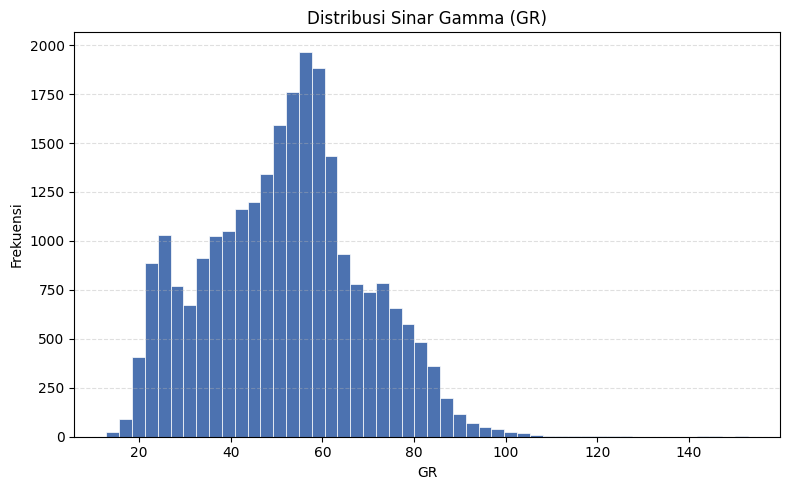

In [11]:
def plot_histogram(series, title, xlabel, bins=50, color="#4C72B0"):
    data = series.dropna()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(data, bins=bins, color=color, edgecolor="white", linewidth=0.5)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frekuensi")
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)

    fig.tight_layout()
    return fig, ax

fig, ax = plot_histogram(df_use["GR"], title="Distribusi Sinar Gamma (GR)", xlabel="GR")
plt.show()

**Interpretation:**

Histogram tersebut menunjukkan sebaran nilai **Gamma Ray (`GR`)** pada dataset sumur.

1. Pemusatan Data & Puncak Utama

    * Puncak tertinggi berada di sekitar **GR 55–60** dengan frekuensi mendekati **2.000 data**.
    * Sebagian besar nilai terpusat di rentang sekitar **35–75**, sejalan dengan rata-rata (51,9) dan median (~52,7) pada ringkasan statistik sebelumnya.

2. Kemiringan (*Skewness*) & Ekor Panjang ke Kanan

    * Bentuk distribusi agak miring ke kanan (*positively/right-skewed*) karena ekor memanjang melewati **GR 80–100** hingga sekitar **150** dengan frekuensi yang sangat kecil.
    * Nilai-nilai tinggi di ekor kanan ini memunculkan sedikit *outlier* atas tanpa mengubah pusat data utama.

3. Pola Sub-puncak / Variasi Lapisan
    * Terlihat ada benjolan/puncak kecil di kisaran **GR 22–26** (sekitar ~1.000 data) sebelum sedikit turun di sekitar **GR 30** lalu naik ke puncak utama.
    * Dalam konteks *well log*, variasi beberapa kelompok nilai ini mencerminkan perbedaan karakteristik lapisan batuan (misalnya batuan ber-GR lebih rendah vs batuan ber-GR menengah/tinggi).


**Intinya:**
  - Nilai `GR` paling banyak berada di kisaran menengah (~55–60), dengan ekor memanjang ke nilai tinggi serta sedikit variasi kelompok nilai di rentang rendah.

### c) Lithological composition & GR distribution by rock type (boxplot)

Komposisi GROUP (litologi):
GROUP
SHETLAND GP.        6026
NORDLAND GP.        5380
HORDALAND GP.       5329
DUNLIN GP.          3517
BAAT GP.            2000
ROGALAND GP.        1362
VIKING GP.          1013
CROMER KNOLL GP.     257
HEGRE GP.            211
Name: count, dtype: int64


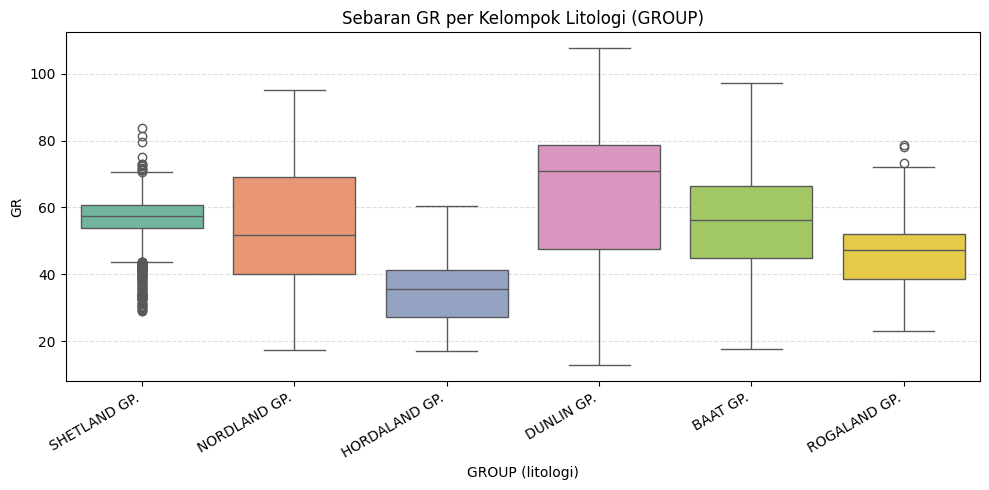

In [13]:
def summarize_and_plot_group_gr(df, group_col="GROUP", value_col="GR", top_n=6):
    counts = df[group_col].value_counts(dropna=False)
    print(f"Komposisi {group_col} (litologi):")
    print(counts)

    top_categories = df[group_col].value_counts().head(top_n).index
    subset = df[df[group_col].isin(top_categories)].copy()
    subset[group_col] = pd.Categorical(
        subset[group_col], categories=top_categories, ordered=True
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(
        data=subset,
        x=group_col,
        y=value_col,
        hue=group_col,
        legend=False,
        palette="Set2",
        ax=ax,
    )

    ax.set_title(f"Sebaran {value_col} per Kelompok Litologi ({group_col})")
    ax.set_xlabel(f"{group_col} (litologi)")
    ax.set_ylabel(value_col)
    ax.tick_params(axis="x", rotation=30)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)

    fig.tight_layout()
    return fig, ax, counts


fig, ax, group_counts = summarize_and_plot_group_gr(df_use, top_n=6)
plt.show()

**Interpretation:**

1. Komposisi Jumlah Data (`GROUP`)

    * **Terbanyak:** `SHETLAND GP.` (6.026), `NORDLAND GP.` (5.380), dan `HORDALAND GP.` (5.329) mendominasi sebagian besar baris dataset.
    * **Menengah:** `DUNLIN GP.` (3.517), `BAAT GP.` (2.000), dan `ROGALAND GP.` (1.362).
    * **Paling sedikit:** `VIKING GP.` (1.013), `CROMER KNOLL GP.` (257), dan `HEGRE GP.` (211).
    
2. Sebaran Nilai `GR` (6 Kelompok Teratas)
    * **GR tertinggi:** `DUNLIN GP.` punya median paling tinggi (sekitar **70**) dan rentang sebaran yang cukup lebar.
    * **GR terendah:** `HORDALAND GP.` berada di posisi paling bawah dengan median sekitar **35**.
    * **Cukup padat & banyak *outlier*:** `SHETLAND GP.` kotaknya sempit (terpusat di sekitar **55–61**, median ~58), tetapi punya banyak titik *outlier* di bawah maupun di atas.
    * **Menengah:** `NORDLAND GP.` (median ~52), `BAAT GP.` (median ~56), dan `ROGALAND GP.` (median ~48) berada di kisaran tengah dengan variasi masing-masing.

**Intinya:**
  - Komposisi data didominasi `SHETLAND`, `NORDLAND`, dan `HORDALAND`, sementara tingkat sinar gamma (`GR`) paling tinggi cenderung ada di `DUNLIN GP.` dan paling rendah di `HORDALAND GP.`.

## Conclusions & Insights

### 📌 Kesimpulan Utama & Wawasan (Insights)

Berdasarkan eksplorasi data log sumur *34/10-16 R* (Laut Utara), berikut adalah beberapa temuan penting:

1. **Kualitas & Kebersihan Data**:
   * Kita berhasil mengidentifikasi dan membuang **8 kolom kosong total (100% NaN)** seperti `RMIC`, `BS`, `SGR`, dan lainnya untuk merampingkan dataset.
   * Kolom porositas neutron (`NPHI`) masih memiliki kekosongan sekitar **33.8%**, yang memerlukan strategi imputasi khusus (seperti median atau interpolasi berbasis kedalaman) jika ingin digunakan dalam pemodelan prediktif.

2. **Tren Kedalaman & Karakteristik Fisik Batuan**:
   * Melalui visualisasi *Track Plot*, terlihat jelas bahwa **Densitas Batuan (`RHOB`) meningkat secara konsisten seiring bertambahnya kedalaman** (`DEPTH_MD`). Hal ini sangat wajar secara geologis karena adanya efek pemadatan (*compaction*) beban batuan di atasnya.
   * Sinar Gamma (`GR`) menunjukkan fluktuasi tajam yang mencerminkan pergantian lapisan litologi (misalnya perselingan antara batupasir/sandstone dengan serpih/shale).

3. **Karakteristik Distribusi Sinar Gamma (`GR`)**:
   * Distribusi `GR` terpusat pada nilai menengah **55–60 API**, dengan bentuk sebaran sedikit miring ke kanan (*right-skewed*).
   * Adanya sub-puncak di area nilai `GR` rendah (~25 API) mengindikasikan kehadiran formasi batuan yang sangat bersih (seperti batupasir bersih atau karbonat).

4. **Asosiasi Litologi (`GROUP`) dengan Sinar Gamma**:
   * **`SHETLAND GP.`**, **`NORDLAND GP.`**, dan **`HORDALAND GP.`** merupakan formasi batuan dominan yang paling banyak ditembus oleh sumur ini.
   * **`DUNLIN GP.`** menunjukkan nilai radiasi sinar gamma tertinggi (median ~70 API), yang menandakan kandungan lempung/shale yang kaya.
   * Sebaliknya, **`HORDALAND GP.`** memiliki nilai `GR` terendah (median ~35 API), yang mengindikasikan formasi batuan yang lebih bersih atau didominasi oleh pasir/karbonat.